# **XGboosting**

## **Level 3**

### This notebook is an extension of the main project file, which contains the full exploratory data analysis of the IPCA series. Here we focus exclusively on the XGBoost model, both without (Level 3) and with exogenous variables (Level 4). The data pipeline is replicated below using the Brazilian Central Bank's SGS API to keep this notebook self-contained, reproducible, and always up to date with the latest available data. At the end, we present a comparative conclusion summarizing the results across both levels and discussing the impact of macroeconomic variables on forecast accuracy.

In [3]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, mean_squared_error
from matplotlib import pyplot as plt

# Configuração para exibir todas as colunas que vamos criar
pd.set_option('display.max_columns', None)

print("Environment setup complete 🚀")

Environment setup complete 🚀


In [5]:

import pandas as pd
import requests

codigos = {
    'ipca': 433,
    'selic': 4189,
    'cambio': 3698,
    'igpm': 189
}

dfs = {}
for nome, codigo in codigos.items():
    url = f'https://api.bcb.gov.br/dados/serie/bcdata.sgs.{codigo}/dados?formato=json'
    headers = {'User-Agent': 'Mozilla/5.0'}
    response = requests.get(url, headers=headers)
    df_temp = pd.DataFrame(response.json())
    df_temp['data'] = pd.to_datetime(df_temp['data'], format='%d/%m/%Y')
    df_temp['valor'] = pd.to_numeric(df_temp['valor'], errors='coerce')
    df_temp = df_temp.rename(columns={'valor': nome})
    dfs[nome] = df_temp

df = dfs['ipca'].copy()
for nome in ['selic', 'cambio', 'igpm']:
    df = df.merge(dfs[nome], on='data', how='inner')

df = df[df['data'] >= '2000-01-01'].copy()
df = df.sort_values('data').reset_index(drop=True)

print(f"DataFrame shape: {df.shape[0]} months recorded.")
print(f"Latest date: {df['data'].max()}")
df.head()

DataFrame shape: 317 months recorded.
Latest date: 2026-05-01 00:00:00


,data,ipca,selic,cambio,igpm
0,2000-01-01,0.62,18.94,1.8037,1.24
1,2000-02-01,0.13,18.87,1.7753,0.35
2,2000-03-01,0.22,18.85,1.7420,0.15
3,2000-04-01,0.42,18.62,1.7682,0.23
4,2000-05-01,0.01,18.51,1.8279,0.31


XGBoost does not natively understand the concept of time.

The first step is to extract numeric information from the date itself.
    - month
    - year

In [6]:
#Creating calendar features
df['ano'] = df['data'].dt.year
df['mes'] = df['data'].dt.month

df.head()

,data,ipca,selic,cambio,igpm,ano,mes
0,2000-01-01,0.62,18.94,1.8037,1.24,2000,1
1,2000-02-01,0.13,18.87,1.7753,0.35,2000,2
2,2000-03-01,0.22,18.85,1.7420,0.15,2000,3
3,2000-04-01,0.42,18.62,1.7682,0.23,2000,4
4,2000-05-01,0.01,18.51,1.8279,0.31,2000,5




 Creating lags

- If we want it to predict next month's IPCA, we need to give it hints 
  from the recent past in the same row.

    - lag1  → IPCA from the previous month
    - lag2  → IPCA from two months ago (basis for justifying lag1, as it 
              captures the short-term trend)
    - lag12 → IPCA from 1 year ago (directly captures annual seasonality)

In [7]:
#Lags para o IPCA 
df['ipca_lag1'] = df['ipca'].shift(1)
df['ipca_lag2'] = df['ipca'].shift(2)
df['ipca_lag12'] = df['ipca'].shift(12)

# Criando os Lags para as variáveis exógenas (Selic, Câmbio e igpm)
df['selic_lag_1'] = df['selic'].shift(1)
df['selic_lag_2'] = df['selic'].shift(2)
df['selic_lag_3'] = df['selic'].shift(3)

df['cambio_lag_1'] = df['cambio'].shift(1)
df['cambio_lag_2'] = df['cambio'].shift(2)
df['cambio_lag_3'] = df['cambio'].shift(3)

df['igpm_lag_1'] = df['igpm'].shift(1)
df['igpm_lag_2'] = df['igpm'].shift(2)
df['igpm_lag_3'] = df['igpm'].shift(3)

df.head(5)

,data,ipca,selic,cambio,igpm,ano,mes,ipca_lag1,ipca_lag2,ipca_lag12,selic_lag_1,selic_lag_2,selic_lag_3,cambio_lag_1,cambio_lag_2,cambio_lag_3,igpm_lag_1,igpm_lag_2,igpm_lag_3
0,2000-01-01,0.62,18.94,1.8037,1.24,2000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2000-02-01,0.13,18.87,1.7753,0.35,2000,2,0.62,NaN,NaN,18.94,NaN,NaN,1.8037,NaN,NaN,1.24,NaN,NaN
2,2000-03-01,0.22,18.85,1.7420,0.15,2000,3,0.13,0.62,NaN,18.87,18.94,NaN,1.7753,1.8037,NaN,0.35,1.24,NaN
3,2000-04-01,0.42,18.62,1.7682,0.23,2000,4,0.22,0.13,NaN,18.85,18.87,18.94,1.7420,1.7753,1.8037,0.15,0.35,1.24
4,2000-05-01,0.01,18.51,1.8279,0.31,2000,5,0.42,0.22,NaN,18.62,18.85,18.87,1.7682,1.7420,1.7753,0.23,0.15,0.35


In [8]:
# 1. Removing rows with null values (NaN)
df_limpo = df.dropna().copy()

# 2. Resetting the index so the count starts from 0 (January 2001)
df_limpo = df_limpo.reset_index(drop=True)

# 3. Checking the results
print(f"Original rows: {len(df)}")
print(f"Rows after cleaning: {len(df_limpo)}")
print(f"First month in the table: {df_limpo['data'].min()}")

df_limpo.head()

Original rows: 317
Rows after cleaning: 305
First month in the table: 2001-01-01 00:00:00


,data,ipca,selic,cambio,igpm,ano,mes,ipca_lag1,ipca_lag2,ipca_lag12,selic_lag_1,selic_lag_2,selic_lag_3,cambio_lag_1,cambio_lag_2,cambio_lag_3,igpm_lag_1,igpm_lag_2,igpm_lag_3
0,2001-01-01,0.57,15.49,1.9545,0.62,2001,1,0.59,0.32,0.62,16.19,16.51,16.60,1.9633,1.9480,1.8796,0.63,0.29,0.38
1,2001-02-01,0.46,15.20,2.0019,0.23,2001,2,0.57,0.59,0.13,15.49,16.19,16.51,1.9545,1.9633,1.9480,0.62,0.63,0.29
2,2001-03-01,0.38,15.39,2.0890,0.56,2001,3,0.46,0.57,0.22,15.20,15.49,16.19,2.0019,1.9545,1.9633,0.23,0.62,0.63
3,2001-04-01,0.58,16.02,2.1925,1.00,2001,4,0.38,0.46,0.42,15.39,15.20,15.49,2.0890,2.0019,1.9545,0.56,0.23,0.62
4,2001-05-01,0.41,16.43,2.2972,0.86,2001,5,0.58,0.38,0.01,16.02,15.39,15.20,2.1925,2.0890,2.0019,1.00,0.56,0.23


Training and test split

In [9]:

data_corte = '2026-01-01'

treino = df_limpo[df_limpo['data'] < data_corte].copy()
teste = df_limpo[df_limpo['data'] >= data_corte].copy()

print(f"Train goes until: {treino['data'].max().strftime('%m/%Y')}")
print(f"Test starts in: {teste['data'].min().strftime('%m/%Y')}")
print(f"Months in test: {len(teste)}")

Train goes until: 12/2025
Test starts in: 01/2026
Months in test: 5


## Pure XGBoost (IPCA Lags Only)


Before introducing macroeconomic variables, we train XGBoost using only IPCA's 
own historical lags and calendar features. This serves as the baseline model, 
isolating the model's capacity to learn autocorrelation and seasonality patterns 
without any external signal.

Hyperparameters are selected via `RandomizedSearchCV` with time-series cross-validation, 
avoiding arbitrary manual choices.

Features used:
- `ipca_lag1`: IPCA from the previous month — short-term momentum
- `ipca_lag2`: IPCA from two months ago — trend confirmation
- `ipca_lag12`: IPCA from 12 months ago — annual seasonality proxy
- `mes` and `ano`: calendar features

In [11]:
# ── LEVEL 3: Pure XGBoost (with Hyperparameter Tuning) ────────────────────────
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit

features_puro = ['mes', 'ano', 'ipca_lag1', 'ipca_lag2', 'ipca_lag12']

X_train_puro = treino[features_puro]
y_train_puro = treino['ipca']
X_test_puro = teste[features_puro]
y_test_puro = teste['ipca']

param_dist = {
    'n_estimators': [200, 500, 1000, 1500],
    'learning_rate': [0.005, 0.01, 0.05, 0.1],
    'max_depth': [3, 4, 5, 6, 8],
    'subsample': [0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.7, 0.8, 0.9, 1.0]
}

tscv = TimeSeriesSplit(n_splits=5)

random_search_puro = RandomizedSearchCV(
    estimator=xgb.XGBRegressor(random_state=42),
    param_distributions=param_dist,
    n_iter=30,
    scoring='neg_mean_absolute_error',
    cv=tscv,
    random_state=42,
    verbose=1,
    n_jobs=-1
)

random_search_puro.fit(X_train_puro, y_train_puro)

print("Best Hiperparameters (level 3):")
print(random_search_puro.best_params_)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best Hiperparameters (level 3):
{'subsample': 0.7, 'n_estimators': 200, 'max_depth': 3, 'learning_rate': 0.01, 'colsample_bytree': 1.0}


In [12]:
modelo_xgb_puro = xgb.XGBRegressor(
    **random_search_puro.best_params_, # ** unpacks the dict into named arguments
    early_stopping_rounds=100,
    random_state=42
)

modelo_xgb_puro.fit(
    X_train_puro, y_train_puro,
    eval_set=[(X_train_puro, y_train_puro), (X_test_puro, y_test_puro)],
    verbose=100
)

[0]	validation_0-rmse:0.38839	validation_1-rmse:0.22486
[100]	validation_0-rmse:0.29525	validation_1-rmse:0.21094
[199]	validation_0-rmse:0.25723	validation_1-rmse:0.21745


,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,1.0
,device,None
,early_stopping_rounds,100
,enable_categorical,False
,eval_metric,None


In [13]:
previsoes_puro = modelo_xgb_puro.predict(X_test_puro)

df_comparativo_puro = pd.DataFrame({
    'Data': teste['data'],
    'IPCA_Real': y_test_puro.values,
    'IPCA_XGBoost_Puro': previsoes_puro
})
df_comparativo_puro['Diferenca'] = (
    df_comparativo_puro['IPCA_Real'] - df_comparativo_puro['IPCA_XGBoost_Puro']
)

mae_puro = mean_absolute_error(y_test_puro, previsoes_puro)
rmse_puro = root_mean_squared_error(y_test_puro, previsoes_puro)

print("--- Level 3: Pure XGBoost Results (Tuned) ---")
print(df_comparativo_puro.to_string(index=False))
print(f"\nMAE:  {mae_puro:.4f}")
print(f"RMSE: {rmse_puro:.4f}")

--- Level 3: Pure XGBoost Results (Tuned) ---
      Data  IPCA_Real  IPCA_XGBoost_Puro  Diferenca
2026-01-01       0.33           0.469505  -0.139505
2026-02-01       0.70           0.507589   0.192411
2026-03-01       0.88           0.519569   0.360431
2026-04-01       0.67           0.564583   0.105417
2026-05-01       0.58           0.442010   0.137990

MAE:  0.1872
RMSE: 0.2081


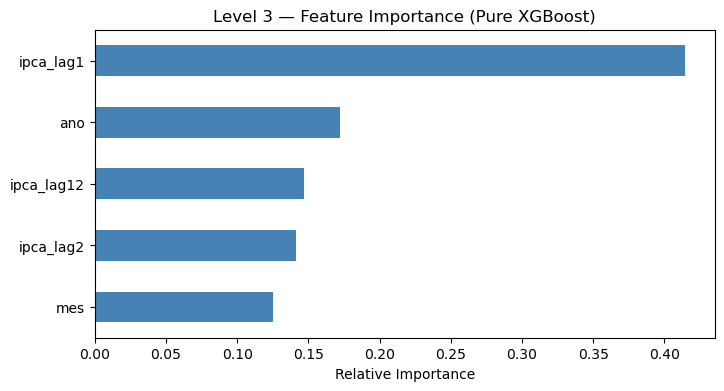

In [14]:
importancia_puro = pd.Series(
    modelo_xgb_puro.feature_importances_, index=features_puro
).sort_values(ascending=True)

plt.figure(figsize=(8, 4))
importancia_puro.plot(kind='barh', color='steelblue')
plt.title('Level 3 — Feature Importance (Pure XGBoost)')
plt.xlabel('Relative Importance')
plt.show()

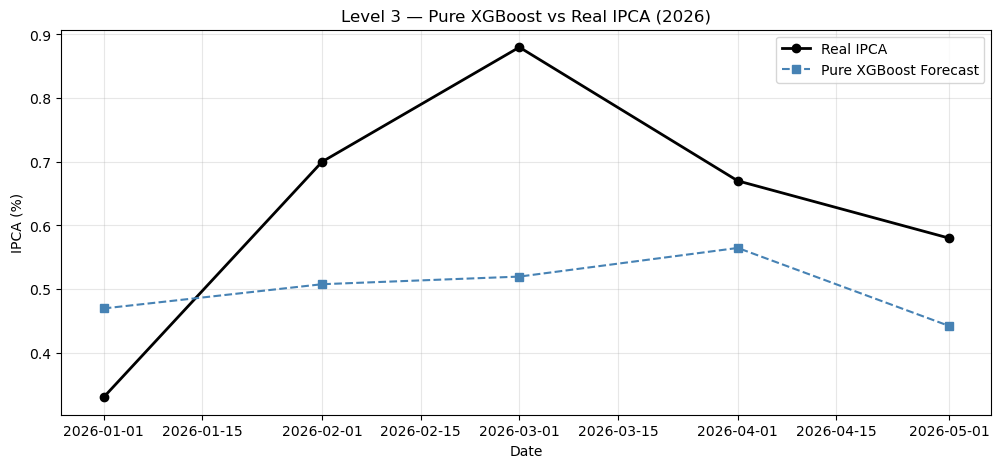

In [15]:
plt.figure(figsize=(12, 5))
plt.plot(df_comparativo_puro['Data'], df_comparativo_puro['IPCA_Real'],
         marker='o', label='Real IPCA', color='black', linewidth=2)
plt.plot(df_comparativo_puro['Data'], df_comparativo_puro['IPCA_XGBoost_Puro'],
         marker='s', label='Pure XGBoost Forecast', color='steelblue', linestyle='--')
plt.title('Level 3 — Pure XGBoost vs Real IPCA (2026)')
plt.xlabel('Date')
plt.ylabel('IPCA (%)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

The pure XGBoost relies exclusively on IPCA's own past values. As expected from 
the ACF/PACF analysis in the EDA notebook, `ipca_lag1` ranked as the most important 
feature by a wide margin, confirming the strong AR(1) structure of the series.

> Results: MAE = 0.1872 | RMSE = 0.2081

This is the best result across all models so far. However, the chart reveals a key limitation: the model closely 
tracked the recent trend in January and February, but underestimated the sharp 
spike in March (predicted 0.52% vs real 0.88%) and April. This suggests the model 
captures short-term momentum well, but struggles to anticipate abrupt movements 
with no precedent in the immediate past.

This result establishes a strong baseline: any improvement from Level 5 (with 
exogenous variables and proper tuning) must beat this MAE to justify the added 
complexity.

## Level 4 — XGBoost with Exogenous Variables

We now expand the feature set to include lagged macroeconomic variables: SELIC, 
exchange rate, and IGP-M. Unlike Prophet's `add_regressor`, XGBoost receives these 
variables already shifted by 1 to 3 months, respecting the real-world lag between 
monetary policy decisions and their effect on inflation.

As in Level 3, hyperparameters are selected via `RandomizedSearchCV` with 
time-series cross-validation.

Features used (in addition to Level 3's set):
- `selic_lag_1/2/3`: SELIC rate, lagged 1 to 3 months
- `cambio_lag_1/2/3`: USD/BRL exchange rate, lagged 1 to 3 months
- `igpm_lag_1/2/3`: IGP-M, lagged 1 to 3 months

In [18]:
# ── LEVEL 4: XGBoost with Exogenous Variables (with Hyperparameter Tuning) ────
features = [col for col in df_limpo.columns if 'lag' in col or col in ['mes', 'ano']]

X_train = treino[features]
y_train = treino['ipca']
X_test = teste[features]
y_test = teste['ipca']

print(f"The model will use the following hints: {features}")

random_search_reg = RandomizedSearchCV(
    estimator=xgb.XGBRegressor(random_state=42),
    param_distributions=param_dist,
    n_iter=30,
    scoring='neg_mean_absolute_error',
    cv=tscv,
    random_state=7,
    verbose=1,
    n_jobs=-1
)

random_search_reg.fit(X_train, y_train)

print("\nBest hiperparameters (Level 4):")
print(random_search_reg.best_params_)

The model will use the following hints: ['ano', 'mes', 'ipca_lag1', 'ipca_lag2', 'ipca_lag12', 'selic_lag_1', 'selic_lag_2', 'selic_lag_3', 'cambio_lag_1', 'cambio_lag_2', 'cambio_lag_3', 'igpm_lag_1', 'igpm_lag_2', 'igpm_lag_3']
Fitting 5 folds for each of 30 candidates, totalling 150 fits

Best hiperparameters (Level 4):
{'subsample': 0.7, 'n_estimators': 200, 'max_depth': 4, 'learning_rate': 0.01, 'colsample_bytree': 0.8}


In [19]:
modelo_xgb = xgb.XGBRegressor(
    **random_search_reg.best_params_,  # ** unpacks the dict into named arguments
    early_stopping_rounds=100,
    random_state=42
)

modelo_xgb.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_test, y_test)],
    verbose=100
)

[0]	validation_0-rmse:0.38791	validation_1-rmse:0.22366
[100]	validation_0-rmse:0.27157	validation_1-rmse:0.22766
[158]	validation_0-rmse:0.23623	validation_1-rmse:0.23182


,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8
,device,None
,early_stopping_rounds,100
,enable_categorical,False
,eval_metric,None


In [20]:
previsoes_2026 = modelo_xgb.predict(X_test)

df_comparativo = pd.DataFrame({
    'Data': teste['data'],
    'IPCA_Real': y_test.values,
    'IPCA_XGBoost': previsoes_2026
})
df_comparativo['Diferenca'] = df_comparativo['IPCA_Real'] - df_comparativo['IPCA_XGBoost']

mae_final = mean_absolute_error(y_test, previsoes_2026)
rmse_final = root_mean_squared_error(y_test, previsoes_2026)

print("--- Level 4: XGBoost + Exogenous Variables Results (Tuned) ---")
print(df_comparativo.to_string(index=False))
print(f"\nMAE:  {mae_final:.4f}")
print(f"RMSE: {rmse_final:.4f}")

--- Level 4: XGBoost + Exogenous Variables Results (Tuned) ---
      Data  IPCA_Real  IPCA_XGBoost  Diferenca
2026-01-01       0.33      0.458113  -0.128113
2026-02-01       0.70      0.473129   0.226871
2026-03-01       0.88      0.491937   0.388063
2026-04-01       0.67      0.524920   0.145080
2026-05-01       0.58      0.524543   0.055457

MAE:  0.1887
RMSE: 0.2203


### Level 4 — Interpretation

> Results: MAE = 0.1887 | RMSE = 0.2203

Compared to Level 3 (MAE = 0.1872), the exogenous variables produced virtually 
identical aggregate accuracy after proper hyperparameter tuning a gap of only 
0.0015 in MAE. However, the visual comparison reveals a meaningful difference: 
Level 4 produces a smoother, more stable forecast curve, while Level 3 overshoots 
in April and drops sharply in May. Notably, IGP-M lag 1 and lag 2 ranked as the 
second and third most important features, confirming that wholesale price movements 
carry real predictive signal for consumer inflation, even when aggregate metrics 
appear similar.

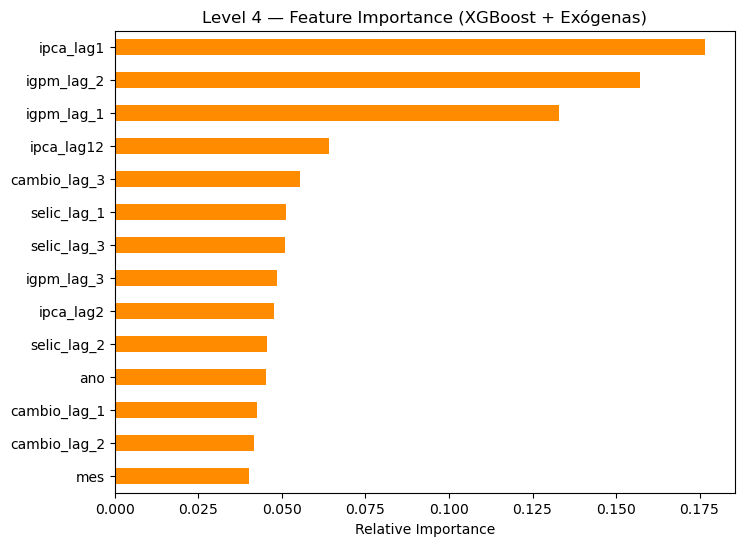

In [21]:
importancia = pd.Series(
    modelo_xgb.feature_importances_, index=features
).sort_values(ascending=True)

plt.figure(figsize=(8, 6))
importancia.plot(kind='barh', color='darkorange')
plt.title('Level 4 — Feature Importance (XGBoost + Exógenas)')
plt.xlabel('Relative Importance')
plt.show()

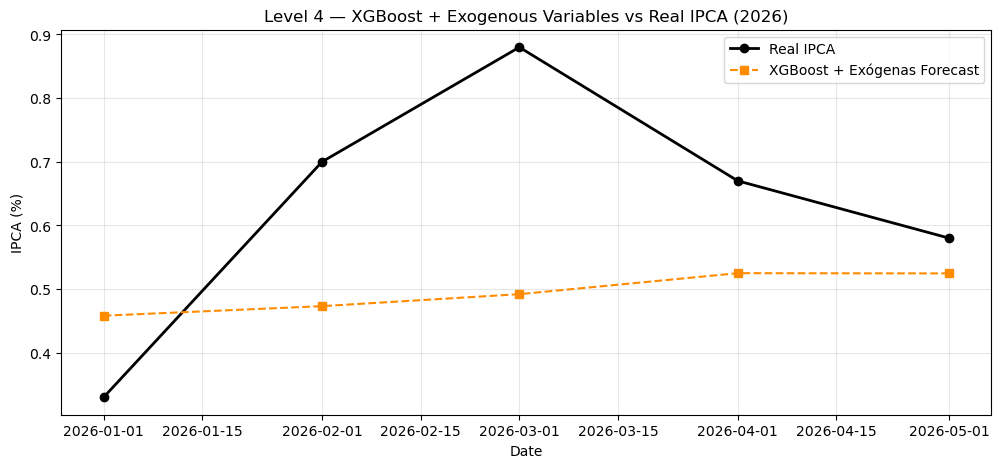

In [22]:
plt.figure(figsize=(12, 5))
plt.plot(df_comparativo['Data'], df_comparativo['IPCA_Real'],
         marker='o', label='Real IPCA', color='black', linewidth=2)
plt.plot(df_comparativo['Data'], df_comparativo['IPCA_XGBoost'],
         marker='s', label='XGBoost + Exógenas Forecast', color='darkorange', linestyle='--')
plt.title('Level 4 — XGBoost + Exogenous Variables vs Real IPCA (2026)')
plt.xlabel('Date')
plt.ylabel('IPCA (%)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

COMPARISON OF LEVEL 3 VS LEVEL 4

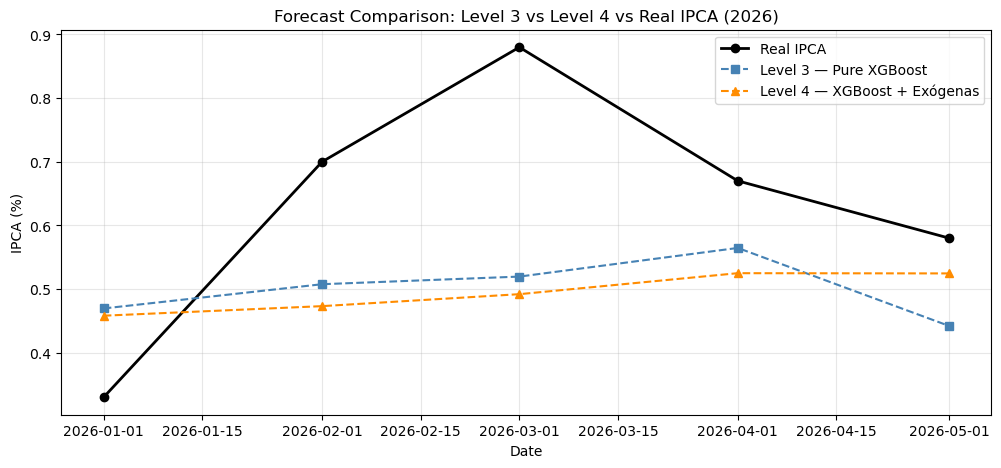

In [23]:
plt.figure(figsize=(12, 5))

plt.plot(df_comparativo['Data'], df_comparativo['IPCA_Real'],
         marker='o', label='Real IPCA', color='black', linewidth=2)

plt.plot(df_comparativo_puro['Data'], df_comparativo_puro['IPCA_XGBoost_Puro'],
         marker='s', label='Level 3 — Pure XGBoost', color='steelblue', linestyle='--')

plt.plot(df_comparativo['Data'], df_comparativo['IPCA_XGBoost'],
         marker='^', label='Level 4 — XGBoost + Exógenas', color='darkorange', linestyle='--')

plt.title('Forecast Comparison: Level 3 vs Level 4 vs Real IPCA (2026)')
plt.xlabel('Date')
plt.ylabel('IPCA (%)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Live Forecast — June/2026

This section generates a real forecast for the upcoming IPCA release, before the 
official figure is published by IBGE. Both XGBoost models are presented side by 
side — Level 3 (pure lags) and Level 4 (with exogenous variables) — following the 
same approach used in the Prophet notebook.

> **Note:** Since the exogenous variables (SELIC, exchange rate, and IGP-M) for 
> June are not yet available, the most recently recorded values (May/2026) are 
> used as a proxy, consistent with the assumption made in the Prophet Live Forecast.

In [24]:
# ── Live Forecast: Next Month ──────────────────────────────────────────────────
ultima_linha = df_limpo.iloc[-1].copy()
proximo_mes_calc = ultima_linha['data'] + pd.DateOffset(months=1)

vetor_proximo_mes = {
    'mes': proximo_mes_calc.month,
    'ano': proximo_mes_calc.year,
    'ipca_lag1': ultima_linha['ipca'],
    'ipca_lag2': ultima_linha['ipca_lag1'],
    'ipca_lag12': df_limpo.iloc[-12]['ipca'],

    'selic_lag_1': ultima_linha['selic'],
    'selic_lag_2': ultima_linha['selic_lag_1'],
    'selic_lag_3': ultima_linha['selic_lag_2'],

    'cambio_lag_1': ultima_linha['cambio'],
    'cambio_lag_2': ultima_linha['cambio_lag_1'],
    'cambio_lag_3': ultima_linha['cambio_lag_2'],

    'igpm_lag_1': ultima_linha['igpm'],
    'igpm_lag_2': ultima_linha['igpm_lag_1'],
    'igpm_lag_3': ultima_linha['igpm_lag_2']
}

# ── Level 4 (Pure) ─────────────────────────────────────────────────────────────
df_proximo_puro = pd.DataFrame([vetor_proximo_mes])[features_puro]
previsao_proximo_puro = modelo_xgb_puro.predict(df_proximo_puro)[0]

# ── Level 5 (Exogenous) ─────────────────────────────────────────────────────────
df_proximo_reg = pd.DataFrame([vetor_proximo_mes])[features]
previsao_proximo_reg = modelo_xgb.predict(df_proximo_reg)[0]

print(f"--- Live Forecast: {proximo_mes_calc.strftime('%B/%Y')} ---\n")
print(f"Level 4 (Pure XGBoost)      : {previsao_proximo_puro:.4f}%")
print(f"Level 5 (XGBoost + Exógenas): {previsao_proximo_reg:.4f}%")

--- Live Forecast: June/2026 ---

Level 4 (Pure XGBoost)      : 0.4627%
Level 5 (XGBoost + Exógenas): 0.5390%
